In [1]:
# Import the relevant libraries
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import cmasher as cmr
from scipy import optimize
from scipy.optimize import fsolve


In [10]:
class DiagnosticDiagram:

    def __init__(self, kx, omega, params):

        # Assign Attributes
        self.kx = kx  # km^-1
        self.omega = omega  # rad/s
        self.params = params

        # Hydrostatic parameters
        self.wac = params['wac']  # rad/s
        self.cs  = params['cs']  # km/s
        self.g = params['g']  # km/s^2
        self.N = params['N']  # rad/s
        self.H = params['H']  # km

        # Radiative parameters
        self.gamma = params['gamma']  # adiabatic index
        self.dz = params['dz']  # km
        self.tau = params['tau']  # s

        # Magnetic parameters
        self.B = params['B']  # Gauss   
        self.c_alf = params['c_alf']  # km/s                      
        self.epsilon = params['epsilon']
        self.theta = params['theta']  # deg
        self.phi = params['phi']  # deg

        # Define the horizontal wavenumber
        self.kh = self.kx

        # Create meshgrids for calculations
        self.kh_grid, self.omega_grid = np.meshgrid(self.kh, self.omega) # km^-1, rad/s
        self.nu_grid = self.omega_grid/(2*np.pi)  # Hz

        # Create meshgrids for plotting
        self.kh_plot = self.kh_grid*1e3  # Mm^-1
        self.nu_plot = (self.omega_grid/(2*np.pi))*1e3  # mHz

    def fmode_dispersion(self):

        '''
        Purpose
        -------
        Calculate the theoretical frequency of the f-mode as a function of wavenumber (k).

        Inputs
        ------
        None

        Outputs
        -------
        nu: np.array, float:
            Theoretical frequency for input wavenumber.

        Author(s)
        ---------
        Julio M. Morales, August 30, 2022
        '''

        # Calculate omega
        omega = np.sqrt(self.g*np.array(self.kh))

        # Turn angular frequency to temporal
        nu = omega/(2*np.pi)

        return nu
    
    def dispersion(omega, kh, params, model, real, solve_bounds):

        ''' 
        Purpose
        -------
        Calculate the dispersion relation for the internal gravity waves.

        Inputs
        ------
        omega: float
            Angular frequency (rad/s)

        kh: float
            Horizontal wavenumber (km^-1)

        params: dict
            Dictionary containing the input parameters.

        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        real: bool
            Real or imaginary part of the dispersion relation. Options are True or False.

        solve_bounds: bool
            Solve the bounds of the dispersion relation. Options are True or False.

        Outputs
        -------
        eq: np.array, float:
            Theoretical dispersion relation for input parameters.  If solve_bounds is True, the output is the expression required to solve for the boundaries.

        Author(s)
        ---------
        Julio M. Morales, July 10th, 2024
        '''

        # Hydrostatic parameters
        wac = params['wac']
        cs = params['cs']
        g = params['g']
        N = params['N']
        H = params['H']

        # Radiative parameters
        gamma = params['gamma']
        tau = params['tau']

        # Magnetic parameters
        B = params['B']
        c_alf = params['c_alf']
        epsilon = params['epsilon']
        theta = params['theta']
        phi = params['phi']

        # Choose model
        if (model == 'mt1981'):
            if real == True:
                eq = pow(N, 2)*pow(kh, 2)/pow(omega, 2) + pow(omega, 2)/pow(cs, 2) -1/(4*pow(H, 2)) - pow(kh, 2)
            if real == False:
                eq = np.zeros_like(omega)

        if (model == 'sf1966'):
            if real == True:
                eq = (pow(omega, 2) - pow(wac, 2))/pow(cs, 2) - (pow(omega, 2) - pow(N, 2))*pow(kh, 2)/pow(omega, 2)
            if real == False:
                eq = np.zeros_like(omega)

        if (model == 'mt1982'):
            # Define parameterizations
            eta = omega*tau
            h0 = pow(N, 2)*pow(kh, 2)/pow(omega, 2) + pow(omega, 2)/pow(cs, 2) -1/(4*pow(H, 2)) - pow(kh, 2)
            a = h0 + (1 + pow(eta, 2))**(-1) * ((gamma - 1)*pow(omega, 2)/pow(cs, 2) - (pow(N, 2)*pow(kh, 2)/pow(omega, 2)))
            b = eta*(1 + pow(eta, 2))**(-1) * ((gamma - 1)*pow(omega, 2)/pow(cs, 2) - (pow(N, 2)*pow(kh, 2)/pow(omega, 2)))
            if real == True:
                kz_real_sqr = 0.5*(pow(a, 2) + (pow(a, 2) + pow(b, 2))**(1/2))
                eq = kz_real_sqr
            if real == False:
                kz_imag_sqr = 0.5*(-pow(a, 2) + (pow(a, 2) + pow(b, 2))**(1/2))
                eq = kz_imag_sqr
            if solve_bounds == True:
                eq = np.sqrt(eq)

        if (model == 'bunte1993'):
            # Non-magnetic, non-adiabatic case
            if (epsilon == 0.0) and (B == 0.0):
                hr = ((pow(omega, 2) - pow(wac, 2)) / cs**2) + kh**2*((pow(N, 2)/pow(omega, 2)) - 1) - (1/(1 + (omega*tau*gamma)**2))*(pow(kh, 2) - (pow(omega, 4)/pow(g, 2)))*(pow(N, 2)/pow(omega, 2))
                hi = - (omega*tau*gamma/(1 + (omega*tau*gamma)**2))*(pow(kh, 2) - (pow(omega, 4)/pow(g, 2)))*(pow(N, 2)/pow(omega, 2))
            # Exponentially decaying magnetic, non-adiabatic case
            if ((epsilon == 0.0) and (B != 0.0)):
                p1 = (cs**2 + c_alf**2)*omega**2 - cs**2*c_alf**2*kh**2
                p_gamma = (cs**2 + gamma*c_alf**2)*omega**2 - cs**2*c_alf**2*kh**2
                g1 = omega**4 + g**2*((cs**2/(g*H)) - 1)*kh**2
                g_gamma = gamma*omega**4 + gamma*g**2*((cs**2/(gamma*g*H)) - 1)*kh**2
                hr = -(1/(4*H**2)) - kh**2 + (p_gamma*g_gamma + (omega*tau*gamma)**2*p1*g1) / (p_gamma**2 + (omega*tau*gamma)**2*p1**2)
                hi = (omega*tau*gamma)*(p1*g_gamma - p_gamma*g1)/(p_gamma**2 + (omega*tau*gamma)**2*p1**2)            
            if real == True:
                kz_real_sqr = 0.5*(hr + (hr**2 + hi**2)**(1/2))
                eq = kz_real_sqr
            if real == False:
                kz_imag_sqr = 0.5*(-hr + (hr**2 + hi**2)**(1/2))
                eq = kz_imag_sqr
            if solve_bounds == True:
                eq = hr

        if (model == 'nc2009'):
            if solve_bounds == True:
                eq = -N**2*c_alf**2*cs**2*kh**4*np.sin(theta*np.pi/180)**2 + N**2*cs**2*kh**2*omega**2 - c_alf**4*cs**2*kh**6*np.sin(theta*np.pi/180)**4 + c_alf**4*kh**4*omega**2*np.sin(theta*np.pi/180)**2 - c_alf**4*kh**4*wac**2*np.sin(theta*np.pi/180)**2*np.cos(theta*np.pi/180)**2 + 2*c_alf**2*cs**2*kh**4*omega**2*np.sin(theta*np.pi/180)**2 - c_alf**2*kh**2*omega**4*np.sin(theta*np.pi/180)**2 - c_alf**2*kh**2*omega**4 + c_alf**2*kh**2*omega**2*wac**2*np.sin(phi*np.pi/180)**2*np.sin(theta*np.pi/180)**2 + c_alf**2*kh**2*omega**2*wac**2*np.sin(theta*np.pi/180)**2 + c_alf**2*kh**2*omega**2*wac**2*np.cos(theta*np.pi/180)**2 - cs**2*kh**2*omega**4 + omega**6 - omega**4*wac**2

        return eq
    
    def boundary_solver(self, model):

        '''
        Purpose
        -------
        Calculate the boundaries of the dispersion relation.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        Outputs
        -------
        omega_bounds: np.array, float:
            Boundaries of the dispersion relation for input parameters.

        Author(s)
        ---------
        Julio M. Morales, September 30th, 2024
        '''

        # Define a range and step size for finely spaced intervals
        omega_min, omega_max = abs(np.nanmin(self.omega)), abs(np.nanmax(self.omega))
        step_size = (self.omega[1] - self.omega[0])

        # Create intervals using the specified step size
        intervals = [(omega, omega + step_size) for omega in np.arange(omega_min, omega_max, step_size)]

        # Lists to store the roots
        omega_bounds = np.ones((6, len(self.kh)))

        # Unpack the parameters
        cs = self.params['cs']
        N = self.params['N']
        H = self.params['H']

        # Analytic solution from @mihalasInternalGravityWaves1981
        omega1_mt1981 = np.sqrt(2)*np.sqrt(4*cs**2*self.kh**2 + cs**2/H**2 + cs*np.sqrt(-64*H**4*N**2*self.kh**2 + 16*H**4*cs**2*self.kh**4 + 8*H**2*cs**2*self.kh**2 + cs**2)/H**2)/4
        omega2_mt1981 = np.sqrt(2)*np.sqrt(4*cs**2*self.kh**2 + cs**2/H**2 - cs*np.sqrt(-64*H**4*N**2*self.kh**2 + 16*H**4*cs**2*self.kh**4 + 8*H**2*cs**2*self.kh**2 + cs**2)/H**2)/4

        # Loop through the grid
        for i in range(len(self.kh)):

            # List to store roots
            roots = []

            # Choose appropriate solver for the model
            if model == 'mt1982':

                # Find the roots
                root = fsolve(DiagnosticDiagram.dispersion, [omega1_mt1981[i], omega2_mt1981[i]], args = (self.kh[i], self.params, model, True, True), xtol = 0.5)

                # Append the roots
                omega_bounds[0, i] = root[0]
                omega_bounds[1, i] = root[1]
                omega_bounds[2, i] = np.nan
                omega_bounds[3, i] = np.nan
                omega_bounds[4, i] = np.nan
                omega_bounds[5, i] = np.nan
            else:
                # Loop through intervals to find root(s)
                for interval in intervals:
                    try:
                        root, _ = optimize.brentq(DiagnosticDiagram.dispersion, interval[0], interval[1], args=(self.kh[i], self.params, model, True, True), full_output = True)
                        roots.append(root)
                    except ValueError:
                        pass  # No root in this interval

                # Remove duplicates (sometimes the same root can be found in neighboring intervals)
                roots = sorted(set(roots))

                # Ensure roots list has exactly 6 elements
                roots = (roots + [np.nan] * 6)[:6]

                # Append the roots
                omega_bounds[0, i] = roots[0]
                omega_bounds[1, i] = roots[1]
                omega_bounds[2, i] = roots[2]
                omega_bounds[3, i] = roots[3]
                omega_bounds[4, i] = roots[4]
                omega_bounds[5, i] = roots[5]

        return omega_bounds
    
    def kz_model(kz, omega, kh, params, model, real):

        '''
        Purpose
        -------
        Calculate the dispersion relation for the internal gravity waves.

        Inputs
        ------
        kz: float
            Vertical wavenumber (km^-1)

        omega: float
            Angular frequency (rad/s)

        kh: float
            Horizontal wavenumber (km^-1)

        params: dict
            Dictionary containing the input parameters.

        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        real: bool
            Real or imaginary part of the dispersion relation. Options are True or False.

        Outputs
        -------
        eq: np.array, float:
            Theoretical dispersion relation for input parameters.

        Author(s)
        Julio M. Morales, October 6th, 2024
        '''

        # Hydrostatic parameters
        wac = params['wac']
        cs = params['cs']
        N = params['N']

        # Magnetic parameters
        c_alf = params['c_alf']
        theta = params['theta']
        phi = params['phi']

        # Choose model
        if (model == 'nc2009'):
            if real == True:
                c6 = -c_alf**4*cs**2*np.cos(theta*np.pi/180)**4
                c5 = 0
                c4 = -6*c_alf**4*cs**2*kh**2*np.sin(theta*np.pi/180)**2*np.cos(theta*np.pi/180)**2 - c_alf**4*cs**2*kh**2*np.sin(theta*np.pi/180)*np.cos(theta*np.pi/180)**3 + c_alf**4*omega**2*np.cos(theta*np.pi/180)**2 - c_alf**4*wac**2*np.cos(theta*np.pi/180)**4 + 2*c_alf**2*cs**2*omega**2*np.cos(theta*np.pi/180)**2        
                c3 = 0
                c2 = -N**2*c_alf**2*cs**2*kh**2*np.cos(theta*np.pi/180)**2 - c_alf**4*cs**2*kh**4*np.sin(theta*np.pi/180)**4 - c_alf**4*cs**2*kh**4*np.sin(theta*np.pi/180)**3*np.cos(theta*np.pi/180) - 5*c_alf**4*cs**2*kh**4*np.sin(theta*np.pi/180)**2*np.cos(theta*np.pi/180)**2 + c_alf**4*kh**2*omega**2*np.sin(theta*np.pi/180)**2 + c_alf**4*kh**2*omega**2*np.cos(theta*np.pi/180)**2 - c_alf**4*kh**2*wac**2*np.sin(theta*np.pi/180)**2*np.cos(theta*np.pi/180)**2 - c_alf**4*kh**2*wac**2*np.cos(theta*np.pi/180)**4 + 2*c_alf**2*cs**2*kh**2*omega**2*np.sin(theta*np.pi/180)**2 + c_alf**2*cs**2*kh**2*omega**2*np.sin(theta*np.pi/180)*np.cos(theta*np.pi/180) + c_alf**2*cs**2*kh**2*omega**2*np.cos(theta*np.pi/180)**2 - c_alf**2*omega**4*np.cos(theta*np.pi/180)**2 - c_alf**2*omega**4 + 2*c_alf**2*omega**2*wac**2*np.cos(theta*np.pi/180)**2 - cs**2*omega**4
                c1 = 0
                c0 = -N**2*c_alf**2*cs**2*kh**4*np.sin(theta*np.pi/180)**2 + N**2*cs**2*kh**2*omega**2 - c_alf**4*cs**2*kh**6*np.sin(theta*np.pi/180)**4 + c_alf**4*kh**4*omega**2*np.sin(theta*np.pi/180)**2 - c_alf**4*kh**4*wac**2*np.sin(theta*np.pi/180)**2*np.cos(theta*np.pi/180)**2 + 2*c_alf**2*cs**2*kh**4*omega**2*np.sin(theta*np.pi/180)**2 - c_alf**2*kh**2*omega**4*np.sin(theta*np.pi/180)**2 - c_alf**2*kh**2*omega**4 + c_alf**2*kh**2*omega**2*wac**2*np.sin(phi*np.pi/180)**2*np.sin(theta*np.pi/180)**2 + c_alf**2*kh**2*omega**2*wac**2*np.sin(theta*np.pi/180)**2 + c_alf**2*kh**2*omega**2*wac**2*np.cos(theta*np.pi/180)**2 - cs**2*kh**2*omega**4 + omega**6 - omega**4*wac**2
            if real == False:
                c0 = 0
                c1 = 0
                c2 = 0
                c3 = 0
                c4 = 0
                c5 = 0
                c6 = 0

        return c0 + c1*kz + c2*kz**2 + c3*kz**3 + c4*kz**4 + c5*kz**5 + c6*kz**6
    
    def kz_solver(omega, kh, params, model, real):

        '''
        Purpose
        -------
        Calculate the vertical wavenumber of the wave.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        Outputs
        -------
        kz: np.array, float:
            Vertical wavenumber of the wave (km^-1)

        Author(s)
        ---------
        Julio M. Morales, September 30th, 2024
        '''

        # Define a range and step size for finely spaced intervals
        kz_min, kz_max = 0.0, 0.05
        step_size = 0.01

        # Create intervals using the specified step size
        intervals = [(kz, kz + step_size) for kz in np.arange(kz_min, kz_max, step_size)]

        # Arrays to store the solutions to kz_sqr
        kz = np.ones((len(omega), len(kh)))

        # Loop through the grid
        for i in range(len(kh)):

            for j in range(len(omega)):

                # List to store roots
                roots = []

                # Loop through intervals to find root(s)
                for interval in intervals:
                    try:
                        root, _ = optimize.brentq(DiagnosticDiagram.kz_model, interval[0], interval[1], args=(omega[j], kh[i], params, model, real), full_output = True)
                        roots.append(root)
                    except ValueError:
                        pass  # No root in this interval

                # Remove duplicates (sometimes the same root can be found in neighboring intervals)
                roots = sorted(set(roots))

                # Ensure roots list has exactly 6 elements
                roots = (roots + [np.nan] * 6)[:6]

                # Store the roots
                kz[j, i] = roots[0]

        return kz

    def phase_speed(omega, kz):

        '''
        Purpose
        -------
        Calculate the phase speed of the wave.

        Inputs
        ------
        omega: np.array, float
            Angular frequency (rad/s)

        kz: float
            Vertical wavenumber (km^-1)

        Outputs
        -------
        v_phase: np.array, float
            Phase speed of the wave (km/s)

        Author(s)
        ---------
        Julio M. Morales, June 03, 2024
        '''

        # Calculate the phase speed
        v_phase = omega*kz**(-1) # km/s

        return v_phase
    
    def phase_difference(nu, v_phase, dz):

        '''
        Purpose
        -------
        Calculate the phase difference between two points.

        Inputs
        ------
        nu; np.array, float:
            Frequency of the wave (mHz)

        v_phase; np.array, float:
            Phase speed of the wave (km/s)

        dz; float:
            Distance between two points (km)

        Outputs
        -------
        delta_phi; np.array, float:
            Phase difference between two points (rad)

        Author(s)
        ---------
        Julio M. Morales, June 03, 2024
        '''

        # Calculate the phase difference
        delta_phi = 2*np.pi*nu*dz*v_phase**(-1) # rad

        return delta_phi
    
    def diagnostic_diagram(self, model):

        '''
        Purpose
        -------
        Create a diagnostic diagram for a given dispersion relation model.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966', 'mt1982', 'bunte1993', 'nc1009', and 'vj2017'.

        Outputs
        -------
        delta_phi; np.array, float:
            Phase difference between two heights (deg)

        Author(s)
        ---------
        Julio M. Morales, August 30, 2022
        '''

        # Solver for the boundaries of the diagram
        omega_bounds = DiagnosticDiagram.boundary_solver(self, model)

        # Unpack the boundaries
        self.omega1 = omega_bounds[0, :]
        self.omega2 = omega_bounds[1, :]
        self.omega3 = omega_bounds[2, :]
        self.omega4 = omega_bounds[3, :]
        self.omega5 = omega_bounds[4, :]
        self.omega6 = omega_bounds[5, :]

        # Convert omega to nu
        self.nu1 = self.omega1/(2*np.pi)*1e3 # mHz
        self.nu2 = self.omega2/(2*np.pi)*1e3 # mHz
        self.nu3 = self.omega3/(2*np.pi)*1e3 # mHz
        self.nu4 = self.omega4/(2*np.pi)*1e3 # mHz
        self.nu5 = self.omega5/(2*np.pi)*1e3 # mHz
        self.nu6 = self.omega6/(2*np.pi)*1e3 # mHz
    
        # Choose the model
        if model == 'nc2009':
            # Calculate kz on the grids
            kz_real_sqr = pow(DiagnosticDiagram.kz_solver(self.omega, self.kh, self.params, model, True), 2)
            kz_imag_sqr = pow(DiagnosticDiagram.kz_solver(self.omega, self.kh, self.params, model, False), 2)
        else:
            # Calculate kz on the grids
            kz_real_sqr = DiagnosticDiagram.dispersion(self.omega_grid, self.kh_grid, self.params, model, True, False)
            kz_imag_sqr = DiagnosticDiagram.dispersion(self.omega_grid, self.kh_grid, self.params, model, False, False)

        # Evaluate kz
        kz_real_ac = np.sqrt(kz_real_sqr)
        kz_real_agw = -np.sqrt(kz_real_sqr)
        kz_imag_ac = np.sqrt(kz_imag_sqr)
        kz_imag_agw = -np.sqrt(kz_imag_sqr)

        # Calculate the phase speed
        v_real_ac = DiagnosticDiagram.phase_speed(self.omega_grid, kz_real_ac)
        v_real_agw = DiagnosticDiagram.phase_speed(self.omega_grid, kz_real_agw)
        v_imag_ac = DiagnosticDiagram.phase_speed(self.omega_grid, kz_imag_ac)
        v_imag_agw = DiagnosticDiagram.phase_speed(self.omega_grid, kz_imag_agw)

        # Calculate the phase differences
        self.delta_phi_real_ac = DiagnosticDiagram.phase_difference(self.nu_grid, v_real_ac, self.dz)
        self.delta_phi_real_agw = DiagnosticDiagram.phase_difference(self.nu_grid, v_real_agw, self.dz)
        self.delta_phi_imag_ac = DiagnosticDiagram.phase_difference(self.nu_grid, v_imag_ac, self.dz)
        self.delta_phi_imag_agw = DiagnosticDiagram.phase_difference(self.nu_grid, v_imag_agw, self.dz)

        # Find indices in the AGW region
        agw_indices = np.where(self.nu_plot < (self.nu2))

        # Replace them with the AGW solutions
        self.delta_phi_real_ac[agw_indices] = self.delta_phi_real_agw[agw_indices]

        # Redefine the total solution
        self.delta_phi = self.delta_phi_real_ac*180/np.pi # deg          

        return self.delta_phi

    def plot_diagnostic_diagram(self, model):

        '''
        Purpose
        -------
        Create a diagnostic diagram for AGWS.

        Inputs
        ------
        model: str
            Dispersion relation model to be used. Options are 'mt1981', 'sf1966','mt1982', 'bunte1993', 'nc2009', and 'vj2017.

        Outputs
        -------
        None

        Author(s)
        ---------
        Julio M. Morales, June 03rd, 2024
        '''

        # Create figure features
        fontsize = 15
        frequency_label = r'$\nu\,\left[\mathrm{mHz}\right]$'
        wavenumber_label = r'$k_{h}\,\left[\mathrm{Mm}^{-1}\right]$'
        colorbar_label = r'$\Delta\phi\,\left[\mathrm{deg}\right]$'
        cmap_name = cmr.fusion
            
        # Min and Max scaling for colorbar
        vmin = -80
        vmax = 80

        # Determine which model to use
        if model == 'mt1981':
            title = '(M&T, 1981)'
        if model == 'sf1966':
            title = '(SF, 1966)'
        if model == 'mt1982':
            title = '(M&T, 1982)'
        if model == 'bunte1993':
            title = r'$B = $' + f'{self.B:,}' + ' G' + r', $\tau = $' + f'{self.tau:.0f}' + r's, $\epsilon = $' + f'{self.epsilon:.0f}' + ' (B, 1993)'
        if model == 'nc2009':
            title = r'$a = $' + f'{self.c_alf/self.cs:.1f}' + r'$c_s$' +  r', $\theta = $' + f'{self.theta:.0f}' + r'$^\circ$, $\phi = $' + f'{self.phi:.0f}' + r'$^\circ$ (N&C, 2009)'
        if model == 'vj2017':
            title = r'$B = $' + f'{self.B:,}' + ' G (V&J, 2017)'

        # Calculate the theoretical f-mode dispersion relation
        self.fmode_nu = DiagnosticDiagram.fmode_dispersion(self)*1e3 # mHz

        # Make the plot
        plt.rcParams.update({'font.size': fontsize})
        plt.figure(figsize = (9, 8))
        plt.pcolormesh(np.real(self.kh_plot), np.real(self.nu_plot), self.delta_phi, cmap = cmap_name, shading = "auto", norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), rasterized = True)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.fmode_nu), 'gray')
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu4), 'k*', markersize = 3)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu2), 'k*', markersize = 3)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu1), 'k*', markersize = 3)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu3), 'k*', markersize = 3)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu5), 'k*', markersize = 3)
        plt.plot(np.real(self.kh_plot[0]), np.real(self.nu6), 'k*', markersize = 3)
        plt.xlim(0, 7)
        plt.ylim(0, 10)
        plt.xlabel(wavenumber_label)
        plt.ylabel(frequency_label)
        plt.title(title)
        plt.colorbar(label = colorbar_label)
        plt.tight_layout()
        plt.show()

        return

/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_47613/1364600474.py:506: RuntimeWarning: invalid value encountered in sqrt
  kz_real_ac = np.sqrt(kz_real_sqr)
/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_47613/1364600474.py:507: RuntimeWarning: invalid value encountered in sqrt
  kz_real_agw = -np.sqrt(kz_real_sqr)
/var/folders/p5/s6c93d_s38j4sy11sd_js3s40000gn/T/ipykernel_47613/1364600474.py:417: RuntimeWarning: divide by zero encountered in reciprocal
  v_phase = omega*kz**(-1) # km/s


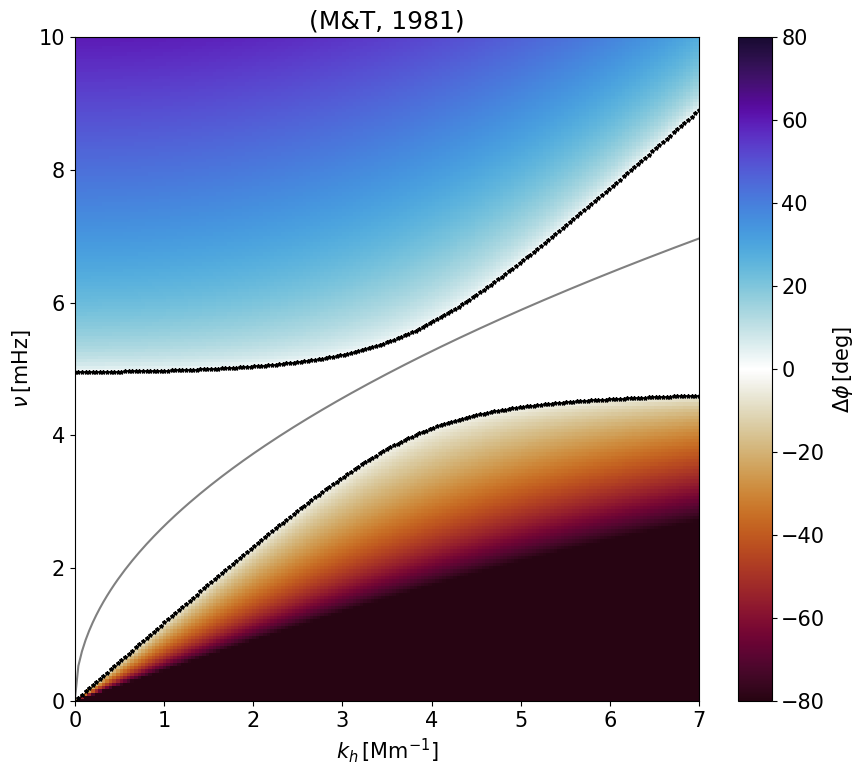

In [12]:
# Create wavenumber and nu grids
kx = np.linspace(1e-10, 8, 200)*1e-3  # Km^-1
omega = np.linspace(1e-10, 10, 200)*2*np.pi*1e-3 # mHz

# Use same constants as @vesaMultiheightObservationsAtmospheric2023 Figure 3
wac = .03116156648591974#5.3e-3*2*np.pi # Hz
cs = 7.821691#7 # km/s
g = 0.274 # km/s^2
H = 125.50221125010206435 # km
gamma = 5/3
N = np.sqrt((gamma - 1)*g/(gamma*H)) # Hz
dz = 150 # km
tau = 200  # s

# Magnetic parameters
B = 10 # G
c_alf = 0.3*cs # km/s
epsilon = 0.0
theta = 80 # deg
phi = 50 # deg
model = 'mt1981'

# Define the input parameters
params = {    'wac': wac, 
               'cs': cs, 
                'g': g, 
                'N': N, 
                'H': H, 
            'gamma': gamma, 
               'dz': dz, 
              'tau': tau, 
                'B': B, 
            'c_alf': c_alf, 
          'epsilon': epsilon, 
            'theta': theta, 
              'phi': phi}

# Initialize the class
dd = DiagnosticDiagram(kx, omega, params)

# Calculate the diagnostic diagram and plot
delta_phi = dd.diagnostic_diagram(model = model)
dd.plot_diagnostic_diagram(model = model)